In [1]:
import pandas as pd
from pathlib import Path

# combined.ipynb writes to Boardgames/Data/; works whether the kernel starts in the repo root or in Boardgames/
PATH = next(p for p in [Path("Data/combined_boardgames.csv"), Path("Boardgames/Data/combined_boardgames.csv")]
            if p.exists() and p.resolve().parent.parent.name == "Boardgames")
df = pd.read_csv(PATH)

# human annotations (ANN*) were deliberately made for only a small sample of games, so they are left out
df = df.drop(columns=df.filter(regex="^ANN").columns)
# BGG catch-all entries that are not actual games (all have year/players/playtime = 0).
# Removed here for now; to be discussed with the group whether to drop them in combined.ipynb instead.
NOT_GAMES = {
    5985: "Miscellaneous Game Accessory",
    18291: "Unpublished Prototype",
    18785: "Miscellaneous Game Magazine",
    21804: "Traditional Card Games",
    22427: "Miscellaneous Game Book",
    23953: "Outside the Scope of BGG",
    96628: "Miscellaneous Game Compilation",
}
assert df.loc[df["BGGId"].isin(NOT_GAMES), "Name"].tolist() == [NOT_GAMES[i] for i in df.loc[df["BGGId"].isin(NOT_GAMES), "BGGId"]]
df = df[~df["BGGId"].isin(NOT_GAMES)].reset_index(drop=True)

print(PATH, df.shape)
df.head()

Data/combined_boardgames.csv (21918, 39)


,BGGId,Name,YearPublished,GameWeight,AvgRating,BayesAvgRating,MinPlayers,MaxPlayers,ComAgeRec,NumOwned,...,Cat:Childrens,description,boardgamemechanic,boardgamedesigner,Mechanics,AI_IsCoherent,AI_ClearObjective,AI_ClearWin,AI_MultipInteract,AI_Confidence
0,1,Die Macher,1986,4.3206,7.61428,7.10363,3,5,14.366667,7498,...,0,Die Macher is a game about seven sequential po...,"['Alliances', 'Area Majority / Influence', 'Au...",['Karl-Heinz Schmiel'],"['Alliances', 'Area Majority / Influence', 'Au...",1.0,1.0,1.0,1.0,2.0
1,2,Dragonmaster,1981,1.9630,6.64537,5.78447,3,4,NaN,1285,...,0,Dragonmaster is a trick-taking card game based...,['Trick-taking'],"['G. W. ""Jerry"" D\'Arcey']",['Trick-taking'],1.0,1.0,1.0,1.0,3.0
2,3,Samurai,1998,2.4859,7.45601,7.23994,2,4,9.307692,15578,...,0,Samurai is set in medieval Japan. Players comp...,"['Area Majority / Influence', 'Hand Management...",['Reiner Knizia'],"['Area Majority / Influence', 'Hand Management...",1.0,1.0,1.0,1.0,3.0
3,4,Tal der Könige,1992,2.6667,6.60006,5.67954,2,4,13.000000,638,...,0,When you see the triangular box and the luxuri...,"['Action Points', 'Area Majority / Influence',...",['Christian Beierer'],"['Action Points', 'Area Majority / Influence',...",1.0,1.0,0.0,1.0,2.0
4,5,Acquire,1964,2.5031,7.33861,7.14189,2,6,11.410256,23735,...,0,"In Acquire, each player strategically invests ...","['Hand Management', 'Investment', 'Market', 'S...",['Sid Sackson'],"['Hand Management', 'Investment', 'Market', 'O...",1.0,1.0,0.0,1.0,2.0


## Missing values stored in other formats
Some columns store "no data" as `0` or as a placeholder value instead of an empty cell, so `isna()` does not count them.
These are converted to `NaN` here so the rest of the analysis counts them as missing.

| Column | Coded as | Why it is treated as missing |
|---|---|---|
| `YearPublished` | `0` | There is no year 0; BGG uses 0 when the year is unknown (real ancient games have negative years) |
| `GameWeight` | `0` | Community-voted complexity (1–5); 0 occurs exactly when `NumWeightVotes == 0` |
| `MinPlayers`, `MaxPlayers` | `0` | A game cannot be played by 0 players |
| `MfgPlaytime` | `0` | A game cannot take 0 minutes |
| `MfgAgeRec` | `0` | Manufacturer's minimum age not given (ambiguous: could mean "all ages", but only 1 game uses age 1) |
| `boardgamedesigner` | `['(Uncredited)']` | BGG placeholder when no designer is known (games with uncredited *plus* a named designer are kept) |

Zeros in count columns (`NumOwned`, `NumWant`, `NumWish`, `NumWeightVotes`, `NumAlternates`, `NumExpansions`, `NumImplementations`), the 0/1 flag columns (`Cat:*`, `Kickstarted`, `IsReimplementation`) and the `AI_*` labels are real values and are left unchanged.

There are 193 games with `YearPublished = 0`. Most are genuinely undated games, but 7 aren't games at all, and those should probably be removed from the dataset.

**1. 7 BGG catch-all entries that aren't games (remove these)**

| BGGId | Name | Ratings |
|---|---|---|
| 21804 | Traditional Card Games | 933 |
| 18291 | Unpublished Prototype | 886 |
| 23953 | Outside the Scope of BGG | 591 |
| 5985 | Miscellaneous Game Accessory | 224 |
| 96628 | Miscellaneous Game Compilation | 195 |
| 22427 | Miscellaneous Game Book | 41 |
| 18785 | Miscellaneous Game Magazine | 33 |

BGG uses these pages to file ratings and items that don't belong to a specific game. All 7 have 0 for year, min players, max players and playtime. They'd skew any analysis, and they also explain some of the zeros in `MinPlayers` and `MaxPlayers`. As far as I can find, these 7 are the only entries of this kind in the dataset.

**2. Traditional and folk games, about 110 games (genuinely undated)**

These have no known year or inventor, so BGG lists the designer as "(Uncredited)". They include:
- card games: War, Go Fish, Crazy Eights, Cheat, Durak, Mao, Big Two, Golf, Whist and Euchre variants, Truco, Koi-Koi, Baccarat
- dice games: Poker Dice, Farkle, Dice 10,000
- board and abstract games: Carrom, Mahjong, Bao, Changgi, Makruk, Surakarta, Hasami Shogi, Seega, Nim, Twelve Men's Morris
- party games: Eat Poop You Cat, Celebrities, Fictionary, Who Am I?

For these, the year is truly unknowable, not left out by mistake. That's why missing year and missing designer go together so often.

**3. Modern games where the year just wasn't entered, about 75 games**

Most have a named designer, so they're recent products with an incomplete BGG listing. Examples:
- licensed games: Cat-opoly, Evil Dead 2, The Terminator, Monopoly: My Marvel Heroes
- small or self-published games: Rocket Squad, Wrathborne Champions, Thug Life the Game
- 18 were Kickstarter games

The year could be looked up for these, but they're obscure, with a median of 50 ratings.

**Suggestions:**
- **Exclude the 7 catch-all entries in [combined.ipynb](Boardgames/combined.ipynb)** so they're gone for everyone using the CSV. Since your groupmate maintains that file, it's probably best to agree on it with them first.
- **Keep the traditional games, but don't treat their missing year as an ordinary gap.** If you need a year, "traditional/undated" is better treated as its own category than filled in with a guess.

Shall I add the catch-all exclusion to the missing-data notebook for now, or leave it to the combined notebook?

In [2]:
# placeholder values that mean "missing", per column
HIDDEN_MISSING = {
    "YearPublished": [0],
    "GameWeight": [0],
    "MinPlayers": [0],
    "MaxPlayers": [0],
    "MfgPlaytime": [0],
    "MfgAgeRec": [0],
    "boardgamedesigner": ["['(Uncredited)']"],
}

coded_missing = pd.Series({col: df[col].isin(vals).sum() for col, vals in HIDDEN_MISSING.items()}, name="n_coded_missing")
for col, vals in HIDDEN_MISSING.items():
    mask = df[col].isin(vals)
    df[col] = df[col].mask(mask)
    if pd.api.types.is_numeric_dtype(df[col]) and df[col].dropna().mod(1).eq(0).all():
        df[col] = df[col].astype("Int64")  # keep integer columns as integers despite the NaNs
coded_missing.to_frame()

,n_coded_missing
YearPublished,186
GameWeight,506
MinPlayers,43
MaxPlayers,166
MfgPlaytime,773
MfgAgeRec,1318
boardgamedesigner,1396


In [3]:
# overview of data types and missing values per column
# n_missing includes the placeholder values converted above; n_coded_missing shows how many of them there were
overview = pd.DataFrame({
    "dtype": df.dtypes,
    "n_missing": df.isna().sum(),
    "n_coded_missing": coded_missing.reindex(df.columns).fillna(0).astype(int),
    "pct_missing": (df.isna().mean() * 100).round(2),
}).sort_values("n_missing", ascending=False)
overview

,dtype,n_missing,n_coded_missing,pct_missing
Family,str,15255,0,69.60
ComAgeRec,float64,5529,0,25.23
Mechanics,str,3249,0,14.82
boardgamedesigner,str,2369,1396,10.81
boardgamemechanic,str,1816,0,8.29
MfgAgeRec,Int64,1318,1318,6.01
MfgPlaytime,Int64,773,773,3.53
GameWeight,float64,506,506,2.31
description,str,428,0,1.95
YearPublished,Int64,186,186,0.85


In [4]:
# number of columns per data type
df.dtypes.value_counts()

int64      19
float64     9
str         6
Int64       5
Name: count, dtype: int64

## Mechanics vs boardgamemechanic
`Mechanics` comes from the andrewmvd/board-games dataset, `boardgamemechanic` from jvanelteren/boardgamegeek-reviews (see `combined.ipynb`).

In [5]:
import ast, re

mech = df["Mechanics"].map(lambda s: set(ast.literal_eval(s)), na_action="ignore")
bgm = df["boardgamemechanic"].map(lambda s: set(ast.literal_eval(s)), na_action="ignore")

# where is each column missing?
pd.crosstab(mech.isna(), bgm.isna(), rownames=["Mechanics missing"], colnames=["boardgamemechanic missing"])

boardgamemechanic missing,False,True
Mechanics missing,,
False,18578,91
True,1524,1725


In [6]:
# mechanic names that only appear in one column (spelling/naming differences)
mech_vals = {m for s in mech.dropna() for m in s}
bgm_vals = {m for s in bgm.dropna() for m in s}
print("Only in Mechanics:", sorted(mech_vals - bgm_vals))
print("Only in boardgamemechanic:", sorted(bgm_vals - mech_vals))

Only in Mechanics: ['Action/Event', 'Auction/Bidding', 'Card Drafting', 'Deck Bag and Pool Building', 'Drafting', 'I Cut You Choose', 'Multiple-Lot Auction', 'Slide/Push', 'Time Track']
Only in boardgamemechanic: ['Action / Event', 'Auction / Bidding', 'Auction Compensation', 'Auction: Multiple Lot', 'Bids As Wagers', 'Closed Drafting', 'Deck, Bag, and Pool Building', 'Drawing', 'I Cut, You Choose', 'Multi-Use Cards', 'Neighbor Scope', 'Open Drafting', 'Ordering', 'Questions and Answers', 'Resource Queue', 'Slide / Push', 'Spelling', 'Tags', 'Turn Order: Time Track']


In [7]:
# where both are present: compare the sets (exact, and ignoring case/punctuation)
both = mech.notna() & bgm.notna()
norm = lambda s: {re.sub(r"\W", "", m.lower()) for m in s}
m_n, b_n = mech[both].map(norm), bgm[both].map(norm)
pd.Series({
    "both present": both.sum(),
    "identical (raw)": (mech[both] == bgm[both]).sum(),
    "identical (normalised)": (m_n == b_n).sum(),
    "Mechanics subset of bgm": (m_n <= b_n).sum(),
    "bgm subset of Mechanics": (b_n <= m_n).sum(),
    "neither subset": (~(m_n <= b_n) & ~(b_n <= m_n)).sum(),
})

both present               18578
identical (raw)            12600
identical (normalised)     13730
Mechanics subset of bgm    16265
bgm subset of Mechanics    13937
neither subset              2106
dtype: int64

## Missing data vs NumUserRatings
Are games with missing values less popular (fewer user ratings)?

['ComAgeRec', 'boardgamedesigner', 'MfgAgeRec', 'MfgPlaytime', 'GameWeight', 'description', 'YearPublished', 'MaxPlayers', 'MinPlayers']


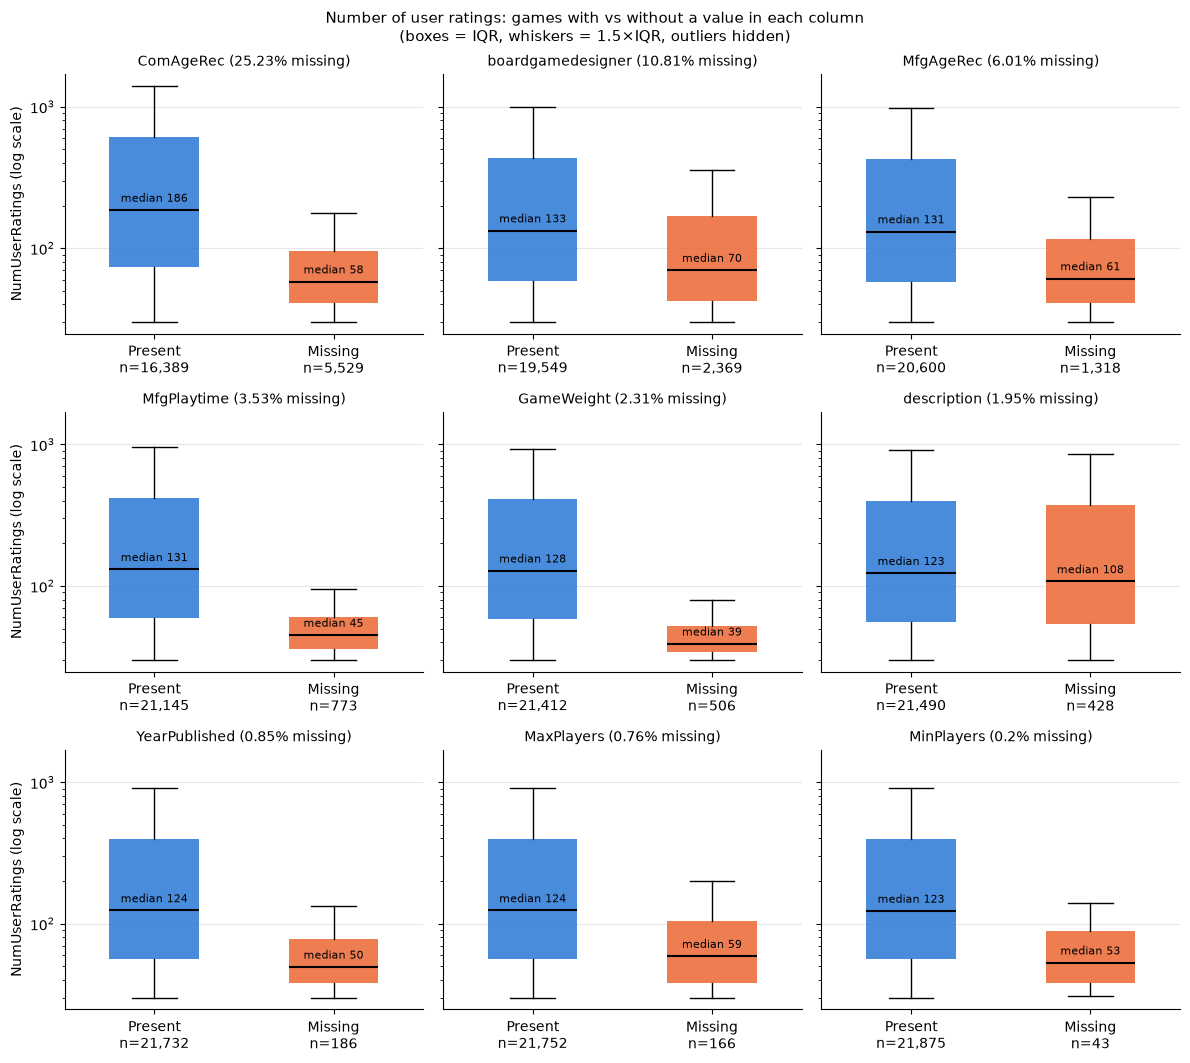

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# columns with missing data used in the plots below. Excluded:
# - the two mechanics columns (compared separately above)
# - Family: a missing value means "not part of a game family/series", so it carries meaning
# - columns with fewer than MIN_MISSING missing values (e.g. AI_* with a single missing row): too few to compare
MIN_MISSING = 30
missing_cols = [c for c in overview.index[overview["n_missing"] >= MIN_MISSING]
                if c not in ("Mechanics", "boardgamemechanic", "Family")]
print(missing_cols)
colors = {"Present": "#2a78d6", "Missing": "#eb6834"}

ncols = 3
nrows = int(np.ceil(len(missing_cols) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.6 * nrows), sharey=True, squeeze=False)

for ax, col in zip(axes.flat, missing_cols):
    groups = {
        "Present": df.loc[df[col].notna(), "NumUserRatings"],
        "Missing": df.loc[df[col].isna(), "NumUserRatings"],
    }
    bp = ax.boxplot(list(groups.values()), tick_labels=[f"{k}\nn={len(v):,}" for k, v in groups.items()],
                    widths=0.5, patch_artist=True, showfliers=False,
                    medianprops={"color": "black", "linewidth": 1.5})
    for patch, k in zip(bp["boxes"], groups):
        patch.set(facecolor=colors[k], alpha=0.85, edgecolor="none")
    for i, v in enumerate(groups.values(), start=1):
        ax.annotate(f"median {v.median():,.0f}", (i, v.median()), xytext=(0, 4),
                    textcoords="offset points", ha="center", va="bottom", fontsize=8)
    ax.set_yscale("log")
    ax.set_title(f"{col} ({overview.loc[col, 'pct_missing']}% missing)", fontsize=10)
    ax.grid(axis="y", color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.flat[len(missing_cols):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("NumUserRatings (log scale)")

fig.suptitle("Number of user ratings: games with vs without a value in each column\n(boxes = IQR, whiskers = 1.5×IQR, outliers hidden)", fontsize=11)
fig.tight_layout()
plt.show()

In [9]:
# median NumUserRatings for present vs missing, per column
pd.DataFrame({
    col: {
        "n_missing": df[col].isna().sum(),
        "median_present": df.loc[df[col].notna(), "NumUserRatings"].median(),
        "median_missing": df.loc[df[col].isna(), "NumUserRatings"].median(),
    }
    for col in missing_cols
}).T.astype(int)

,n_missing,median_present,median_missing
ComAgeRec,5529,186,58
boardgamedesigner,2369,133,70
MfgAgeRec,1318,131,61
MfgPlaytime,773,131,45
GameWeight,506,128,39
description,428,123,107
YearPublished,186,124,49
MaxPlayers,166,124,59
MinPlayers,43,123,53


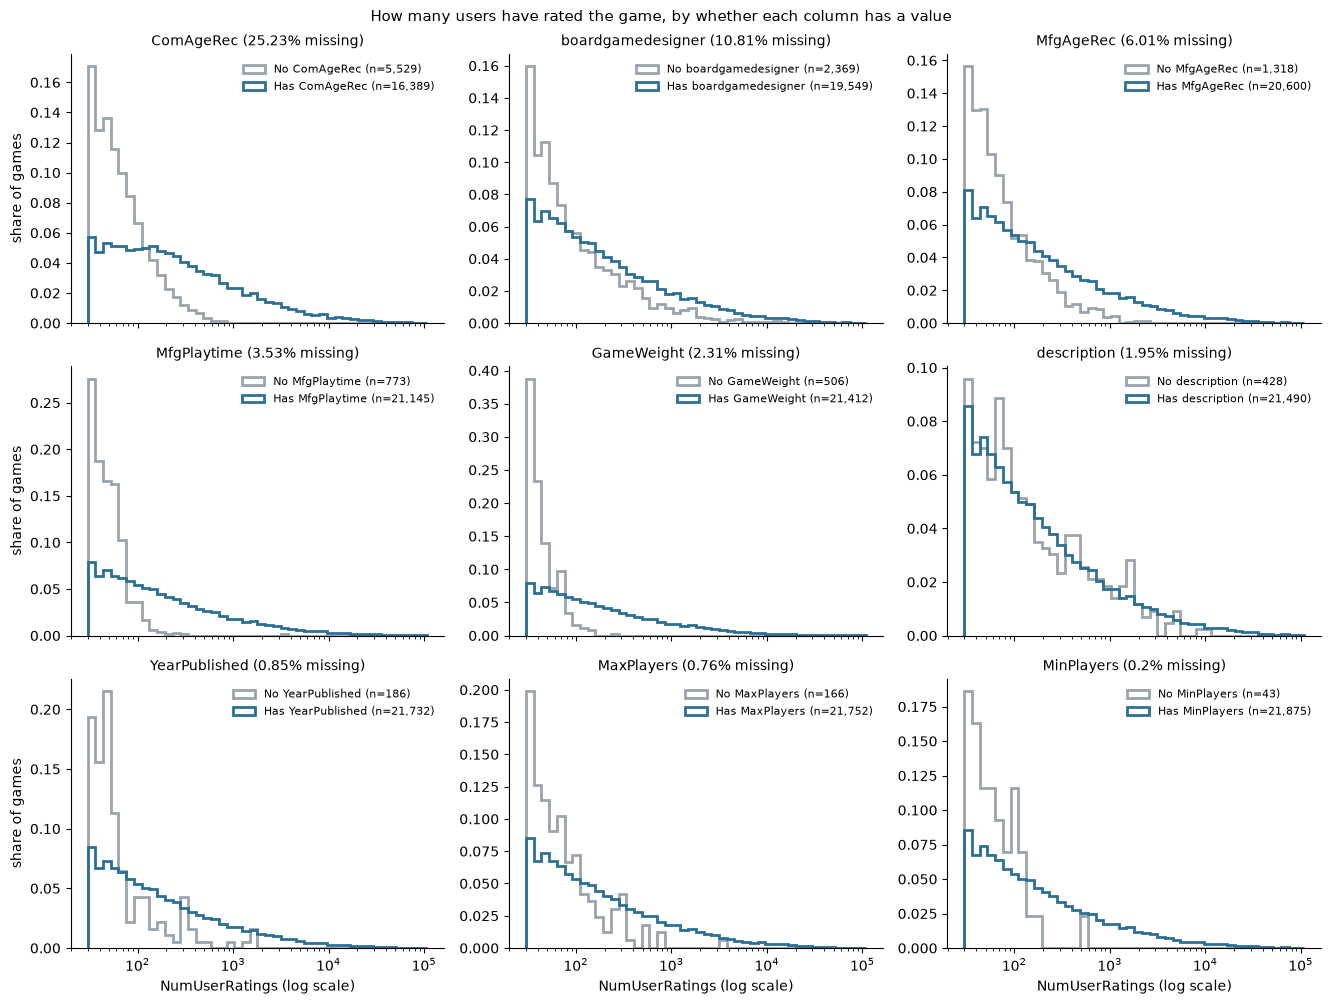

In [10]:
# distribution of NumUserRatings for games with vs without a value, one panel per column
bins = np.logspace(np.log10(df["NumUserRatings"].min()), np.log10(df["NumUserRatings"].max()), 45)

fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.4 * nrows), sharex=True, squeeze=False)
for ax, col in zip(axes.flat, missing_cols):
    for label, mask, color in [(f"No {col}", df[col].isna(), "#9aa3ad"),
                               (f"Has {col}", df[col].notna(), "#2b6f94")]:
        x = df.loc[mask, "NumUserRatings"]
        ax.hist(x, bins=bins, weights=np.full(len(x), 1 / len(x)), histtype="step",
                linewidth=2, color=color, label=f"{label} (n={len(x):,})")
    ax.set_xscale("log")
    ax.set_title(f"{col} ({overview.loc[col, 'pct_missing']}% missing)", fontsize=10)
    ax.legend(frameon=False, fontsize=8)
    ax.spines[["top", "right"]].set_visible(False)

for ax in axes.flat[len(missing_cols):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("share of games")
for ax in axes[-1, :]:
    ax.set_xlabel("NumUserRatings (log scale)")

fig.suptitle("How many users have rated the game, by whether each column has a value", fontsize=11)
fig.tight_layout()
plt.show()

## Do the same rows have missing data across features?
Covers the 9 columns used in the plots (`Family` and the mechanics columns excluded), with `0`/`(Uncredited)` placeholders counted as missing.
The heatmap below is read row by row: of the games missing the row's column, the share that also miss each other column. The "overall" value under each column name is its missing rate across all games, so a cell well above it means the two tend to be missing together.

**Overall:** 13,793 games (62.9%) have none of the 9 columns missing. Most incomplete games miss only one column, and only 640 games (2.9%) miss three or more.
The most common patterns are only `ComAgeRec` (3,813 games, 17.4%), only `boardgamedesigner` (894) and only `MfgAgeRec` (747).

The missing values fall into four groups that match where the data comes from:

**1. Community votes: `ComAgeRec` and `GameWeight`**
- 86% of games without a `GameWeight` (437 of 506) also lack `ComAgeRec`, against 25% overall.
- The reverse is weak (8%): `ComAgeRec` is missing far more often, so missing `GameWeight` is almost a subset of missing `ComAgeRec`.
- Both depend on users voting, which is why both are tied to `NumUserRatings`.
- Because `ComAgeRec` is the most common gap and is tied to popularity, games missing any other column are also missing it more often than average (37–49%).

**2. Source dataset: `description` and `boardgamedesigner`**
- Every game missing `description` is also missing `boardgamedesigner`. These are the ~428 games not in the jvanelteren dataset (also the source of `boardgamemechanic`).
- `boardgamedesigner` is missing for 2,369 games in total: those ~428, about 545 that are in the source but have no designer, and 1,396 listed as `(Uncredited)`.

**3. Undated traditional games: `YearPublished` and `boardgamedesigner`**
- 70% of games with no year also have no designer. These are mostly traditional/folk games (War, Go Fish, Mahjong, Mancala variants) whose year and designer are genuinely unknown, not missing by mistake.

**4. Manufacturer details: `MinPlayers`, `MaxPlayers`, `MfgPlaytime`, `MfgAgeRec`**
- 79% of games without `MinPlayers` also lack `MaxPlayers`, and 56% lack `MfgPlaytime` (overall rates under 4%). These look like incomplete BGG listings.
- `MaxPlayers` is more often missing on its own (132 of 166 games), possibly for games without a fixed maximum.
- `MfgAgeRec` is only loosely linked to the others (14–25%), so a missing manufacturer age is mostly an isolated gap.

In [11]:
is_missing = df[missing_cols].isna()

# number of missing features per game
print(is_missing.sum(axis=1).value_counts().sort_index().rename("n_games").rename_axis("n_missing_features"))

# most common combinations of missing features (True = missing)
patterns = is_missing.value_counts().rename("n_games").reset_index()
patterns["pct"] = (patterns["n_games"] / len(df) * 100).round(2)
patterns.head(15)

n_missing_features
0    13793
1     5738
2     1747
3      508
4      107
5       19
6        3
7        3
Name: n_games, dtype: int64


,ComAgeRec,boardgamedesigner,MfgAgeRec,MfgPlaytime,GameWeight,description,YearPublished,MaxPlayers,MinPlayers,n_games,pct
0,False,False,False,False,False,False,False,False,False,13793,62.93
1,True,False,False,False,False,False,False,False,False,3813,17.40
2,False,True,False,False,False,False,False,False,False,894,4.08
3,False,False,True,False,False,False,False,False,False,747,3.41
4,True,True,False,False,False,False,False,False,False,518,2.36
5,True,False,False,False,True,False,False,False,False,290,1.32
6,False,True,False,False,False,True,False,False,False,248,1.13
7,True,False,True,False,False,False,False,False,False,194,0.89
8,False,False,False,True,False,False,False,False,False,185,0.84
9,True,False,False,True,False,False,False,False,False,140,0.64


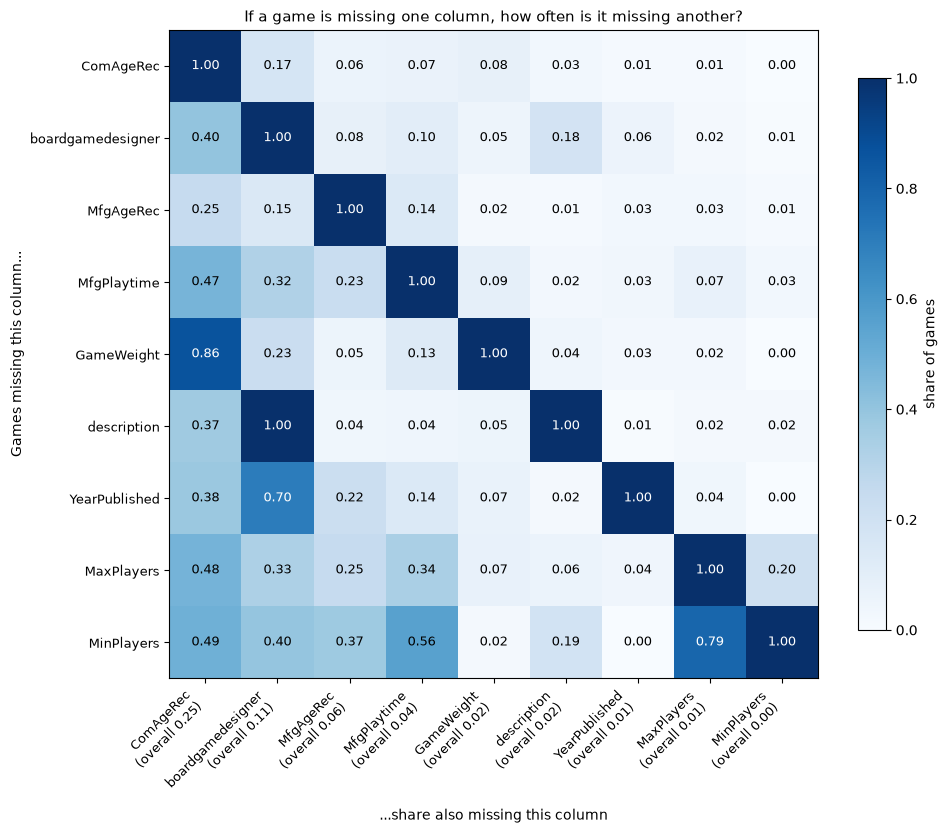

In [12]:
# P(column is missing | row-column is missing), compared with the column's overall missing rate
cond = pd.DataFrame(
    {b: {a: (is_missing[a] & is_missing[b]).sum() / is_missing[a].sum() for a in missing_cols} for b in missing_cols}
)

fig, ax = plt.subplots(figsize=(10, 8.5))
im = ax.imshow(cond.values, cmap="Blues", vmin=0, vmax=1)
for i in range(len(missing_cols)):
    for j in range(len(missing_cols)):
        v = cond.iat[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if v > 0.6 else "black")
overall = is_missing.mean()
ax.set_xticks(range(len(missing_cols)),
              [f"{c}\n(overall {overall[c]:.2f})" for c in missing_cols], rotation=45, ha="right", fontsize=9)
ax.set_yticks(range(len(missing_cols)), missing_cols, fontsize=9)
ax.set_xlabel("...share also missing this column")
ax.set_ylabel("Games missing this column...")
ax.set_title("If a game is missing one column, how often is it missing another?", fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.8, label="share of games")
fig.tight_layout()
plt.show()

## Is there a NumUserRatings cutoff below which features tend to be missing?

In [13]:
# missing rate per NumUserRatings band
edges = [30, 40, 50, 60, 75, 100, 125, 150, 200, 250, 300, 400, 500, 750, 1000, 2000, 5000, np.inf]
band = pd.cut(df["NumUserRatings"], edges, right=False)
rate_by_band = is_missing.groupby(band, observed=True).mean()
rate_by_band["n_games"] = band.value_counts().sort_index()
rate_by_band.round(3)

,ComAgeRec,boardgamedesigner,MfgAgeRec,MfgPlaytime,GameWeight,description,YearPublished,MaxPlayers,MinPlayers,n_games
NumUserRatings,,,,,,,,,,
"[30.0, 40.0)",0.500,0.193,0.115,0.111,0.104,0.021,0.020,0.018,0.005,2540
"[40.0, 50.0)",0.471,0.168,0.109,0.087,0.051,0.020,0.022,0.012,0.004,1970
"[50.0, 60.0)",0.442,0.148,0.096,0.086,0.030,0.021,0.017,0.010,0.003,1460
"[60.0, 75.0)",0.397,0.124,0.085,0.058,0.033,0.022,0.012,0.012,0.003,1698
"[75.0, 100.0)",0.369,0.112,0.067,0.027,0.013,0.023,0.005,0.008,0.002,2016
"[100.0, 125.0)",0.266,0.101,0.066,0.020,0.006,0.017,0.006,0.007,0.004,1366
"[125.0, 150.0)",0.232,0.105,0.053,0.005,0.004,0.026,0.004,0.008,0.002,1060
"[150.0, 200.0)",0.179,0.086,0.048,0.003,0.001,0.015,0.003,0.004,0.001,1488
"[200.0, 250.0)",0.141,0.090,0.054,0.002,0.001,0.015,0.002,0.004,0.000,1040


In [14]:
# if you keep only games with at least k ratings: missing rate per column and number of games kept
ks = np.unique(np.logspace(np.log10(30), np.log10(5000), 60).round().astype(int))
kept_rate = pd.DataFrame({k: is_missing[df["NumUserRatings"] >= k].mean() for k in ks}).T
n_kept = pd.Series({k: (df["NumUserRatings"] >= k).sum() for k in ks})

# smallest cutoff at which each column's missing rate among kept games is at or below 5% / 1%
def first_k(col, thr):
    ok = kept_rate.index[kept_rate[col] <= thr]
    return int(ok[0]) if len(ok) else None
pd.DataFrame({
    "missing overall": is_missing.mean().round(3),
    "cutoff for <=5% missing": {c: first_k(c, 0.05) for c in missing_cols},
    "cutoff for <=1% missing": {c: first_k(c, 0.01) for c in missing_cols},
})

,missing overall,cutoff for <=5% missing,cutoff for <=1% missing
ComAgeRec,0.252,202,481.0
boardgamedesigner,0.108,404,NaN
MfgAgeRec,0.060,46,481.0
MfgPlaytime,0.035,30,71.0
GameWeight,0.023,30,46.0
description,0.020,30,2101.0
YearPublished,0.008,30,30.0
MaxPlayers,0.008,30,30.0
MinPlayers,0.002,30,30.0


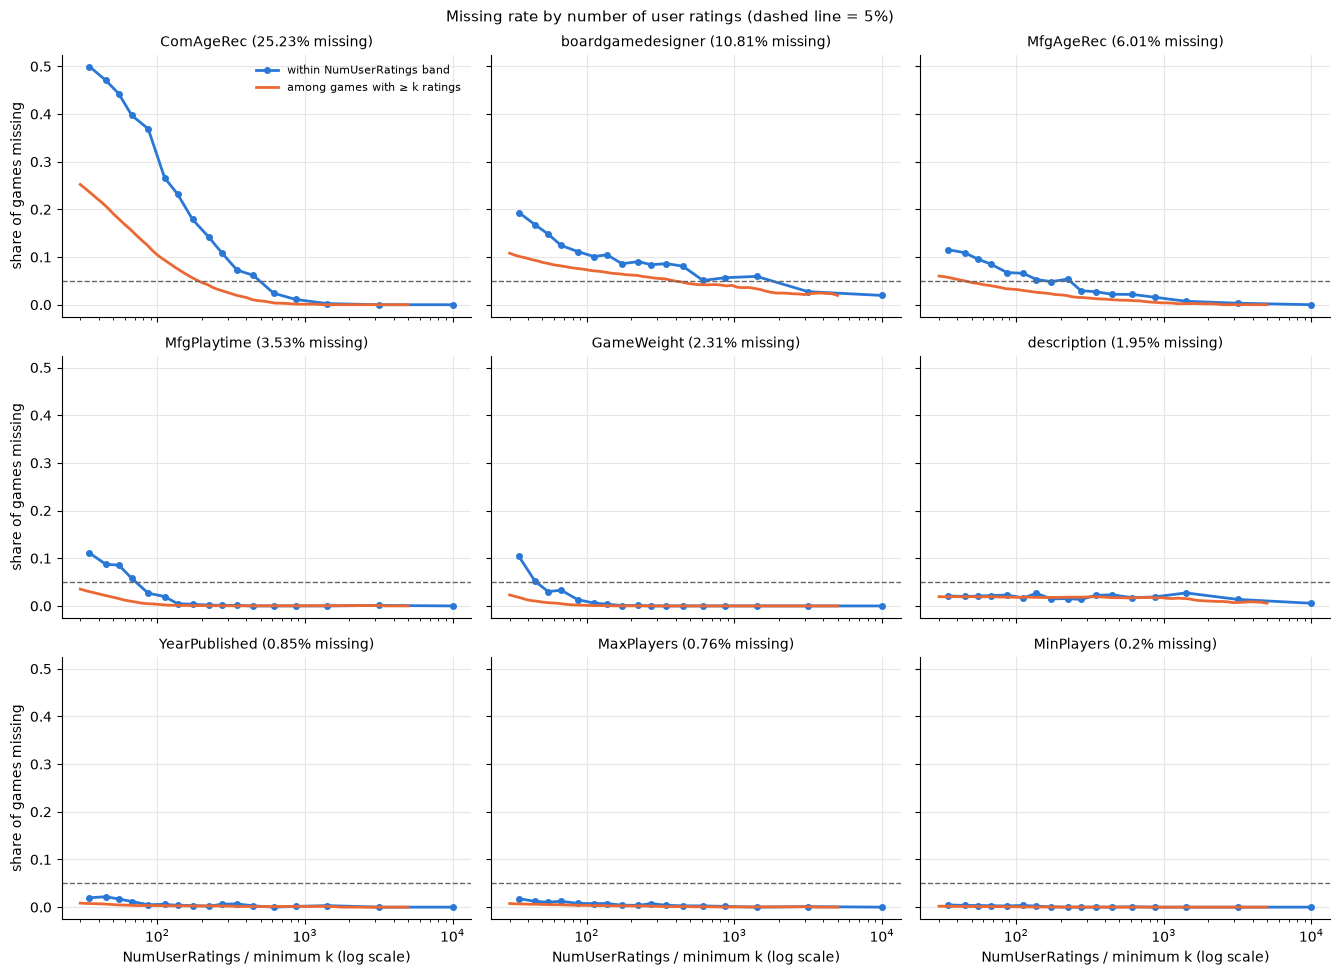

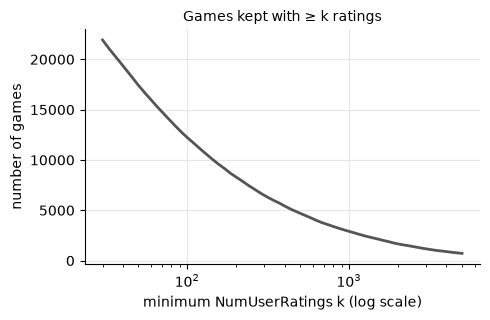

In [15]:
mid = np.sqrt([max(i.left, 30) * min(i.right, 20000) for i in rate_by_band.index])  # geometric band midpoints

# one panel per column: missing rate within each band, and among games with >= k ratings
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 3.3 * nrows), sharex=True, sharey=True, squeeze=False)
for ax, col in zip(axes.flat, missing_cols):
    ax.plot(mid, rate_by_band[col], marker="o", markersize=4, linewidth=2, color="#2a78d6",
            label="within NumUserRatings band")
    ax.plot(kept_rate.index, kept_rate[col], linewidth=2, color="#eb6834", label="among games with ≥ k ratings")
    ax.axhline(0.05, color="0.4", linestyle="--", linewidth=1)
    ax.set_title(f"{col} ({overview.loc[col, 'pct_missing']}% missing)", fontsize=10)
    ax.set_xscale("log")
    ax.grid(color="0.9", linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
for ax in axes.flat[len(missing_cols):]:
    ax.set_visible(False)
for ax in axes[:, 0]:
    ax.set_ylabel("share of games missing")
for ax in axes[-1, :]:
    ax.set_xlabel("NumUserRatings / minimum k (log scale)")
axes.flat[0].legend(frameon=False, fontsize=8)
fig.suptitle("Missing rate by number of user ratings (dashed line = 5%)", fontsize=11)
fig.tight_layout()
plt.show()

# how many games are kept for a given minimum number of ratings
fig, ax = plt.subplots(figsize=(5, 3.3))
ax.plot(n_kept.index, n_kept.values, linewidth=2, color="#555")
ax.set_xscale("log")
ax.set_xlabel("minimum NumUserRatings k (log scale)")
ax.set_ylabel("number of games")
ax.set_title("Games kept with ≥ k ratings", fontsize=10)
ax.grid(color="0.9", linewidth=0.8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()